# Traffic Accident Severity Prediction Using Machine Learning

**Phase 2 – Baseline Implementation**

This project develops a binary classification baseline for predicting fatal and non-fatal road collisions using the UK STATS19 2024 dataset.

The main baseline model is Logistic Regression. A Random Forest classifier is used as an additional comparison model. The implementation also investigates class imbalance and evaluates model performance using accuracy, precision, recall, F1-score and average precision (a summary of precision–recall performance).

The results are discussed in relation to the machine learning methods reported by Amiri et al. (2025). Since the datasets differ, the comparison is methodological rather than a direct reproduction of the original study.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

RANDOM_STATE = 42

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
uploaded = files.upload()

Saving dft-road-casualty-statistics-collision-2024.csv to dft-road-casualty-statistics-collision-2024.csv


In [3]:
filename = "dft-road-casualty-statistics-collision-2024.csv"

df = pd.read_csv(filename, low_memory=False)

print("Dataset shape:", df.shape)
print("\nFirst five records:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nSeverity distribution:")
print(df["collision_severity"].value_counts().sort_index())

Dataset shape: (100927, 44)

First five records:


,collision_index,collision_year,collision_ref_no,location_easting_osgr,location_northing_osgr,longitude,latitude,police_force,collision_severity,number_of_vehicles,...,carriageway_hazards_historic,carriageway_hazards,urban_or_rural_area,did_police_officer_attend_scene_of_accident,trunk_road_flag,lsoa_of_accident_location,enhanced_severity_collision,collision_injury_based,collision_adjusted_severity_serious,collision_adjusted_severity_slight
0,202417H100324,2024,17H100324,449865,528767,-1.22869,54.65155,17,2,1,...,0,0,2,1,2,E01011963,-1,0,1.00000,0.00000
1,202417M110024,2024,17M110024,450069,519269,-1.22715,54.56618,17,3,2,...,-1,0,1,3,2,E01012026,3,1,0.00000,1.00000
2,2024480537342,2024,480537342,531643,180546,-0.10449,51.50852,48,3,1,...,0,0,1,1,2,E01003934,-1,0,0.11617,0.88383
3,202417M105824,2024,17M105824,450326,519173,-1.22319,54.56529,17,3,2,...,-1,0,1,3,2,E01012026,3,1,0.00000,1.00000
4,202417M114324,2024,17M114324,450741,520051,-1.21662,54.57314,17,3,1,...,-1,0,2,1,2,E01035190,3,1,0.00000,1.00000



Column names:
['collision_index', 'collision_year', 'collision_ref_no', 'location_easting_osgr', 'location_northing_osgr', 'longitude', 'latitude', 'police_force', 'collision_severity', 'number_of_vehicles', 'number_of_casualties', 'date', 'day_of_week', 'time', 'local_authority_district', 'local_authority_ons_district', 'local_authority_highway', 'local_authority_highway_current', 'first_road_class', 'first_road_number', 'road_type', 'speed_limit', 'junction_detail_historic', 'junction_detail', 'junction_control', 'second_road_class', 'second_road_number', 'pedestrian_crossing_human_control_historic', 'pedestrian_crossing_physical_facilities_historic', 'pedestrian_crossing', 'light_conditions', 'weather_conditions', 'road_surface_conditions', 'special_conditions_at_site', 'carriageway_hazards_historic', 'carriageway_hazards', 'urban_or_rural_area', 'did_police_officer_attend_scene_of_accident', 'trunk_road_flag', 'lsoa_of_accident_location', 'enhanced_severity_collision', 'collision_

In [4]:
# Keep only valid severity classes
df = df[df["collision_severity"].isin([1, 2, 3])].copy()

# 1 = Fatal, 0 = Non-fatal
df["fatal_target"] = (
    df["collision_severity"] == 1
).astype(int)

features = [
    "speed_limit",
    "number_of_vehicles",
    "day_of_week",
    "road_type",
    "light_conditions",
    "weather_conditions",
    "road_surface_conditions",
    "urban_or_rural_area"
]

X = df[features].copy()
y = df["fatal_target"]

categorical_features = [
    "day_of_week",
    "road_type",
    "light_conditions",
    "weather_conditions",
    "road_surface_conditions",
    "urban_or_rural_area"
]

numerical_features = [
    "speed_limit",
    "number_of_vehicles"
]

# STATS19 uses negative codes for some unknown values
for col in features:
    X[col] = pd.to_numeric(X[col], errors="coerce")
    X.loc[X[col] < 0, col] = np.nan

print("Features:", features)
print("\nTarget distribution:")
print(y.value_counts())

Features: ['speed_limit', 'number_of_vehicles', 'day_of_week', 'road_type', 'light_conditions', 'weather_conditions', 'road_surface_conditions', 'urban_or_rural_area']

Target distribution:
fatal_target
0    99425
1     1502
Name: count, dtype: int64


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(
        strategy="most_frequent"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 80741
Testing samples: 20186


In [6]:
baseline_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE
    ))
])

baseline_model.fit(X_train, y_train)

print("Baseline model trained successfully!")

Baseline model trained successfully!



Logistic Regression Baseline
              precision    recall  f1-score   support

   Non-fatal       0.99      1.00      0.99     19886
       Fatal       0.00      0.00      0.00       300

    accuracy                           0.99     20186
   macro avg       0.49      0.50      0.50     20186
weighted avg       0.97      0.99      0.98     20186



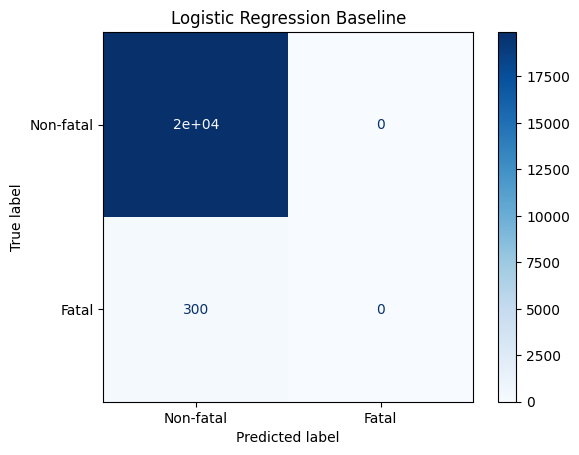

In [7]:
def evaluate_model(name, model, X_test, y_test):
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    results = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_test, predictions, zero_division=0
        ),
        "Average Precision": average_precision_score(
            y_test, probabilities
        )
    }

    print(f"\n{name}")
    print(classification_report(
        y_test, predictions,
        target_names=["Non-fatal", "Fatal"],
        zero_division=0
    ))

    ConfusionMatrixDisplay.from_predictions(
        y_test, predictions,
        display_labels=["Non-fatal", "Fatal"],
        cmap="Blues"
    )
    plt.title(name)
    plt.show()

    return results


baseline_results = evaluate_model(
    "Logistic Regression Baseline",
    baseline_model,
    X_test,
    y_test
)


Class-weighted Logistic Regression
              precision    recall  f1-score   support

   Non-fatal       0.99      0.71      0.83     19886
       Fatal       0.03      0.67      0.07       300

    accuracy                           0.71     20186
   macro avg       0.51      0.69      0.45     20186
weighted avg       0.98      0.71      0.82     20186



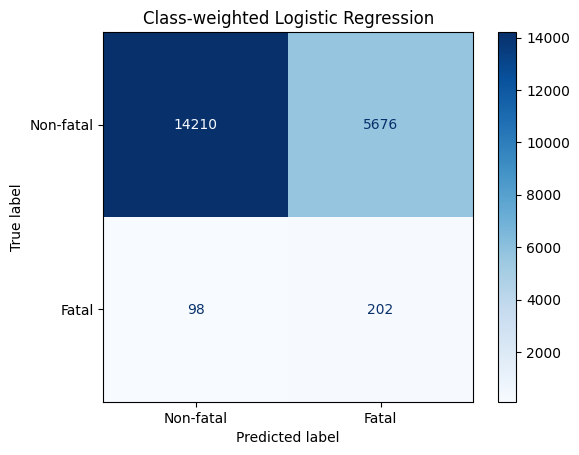

In [8]:
weighted_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=RANDOM_STATE
    ))
])

weighted_model.fit(X_train, y_train)

weighted_results = evaluate_model(
    "Class-weighted Logistic Regression",
    weighted_model,
    X_test,
    y_test
)


Random Forest
              precision    recall  f1-score   support

   Non-fatal       0.99      1.00      0.99     19886
       Fatal       0.00      0.00      0.00       300

    accuracy                           0.99     20186
   macro avg       0.49      0.50      0.50     20186
weighted avg       0.97      0.99      0.98     20186



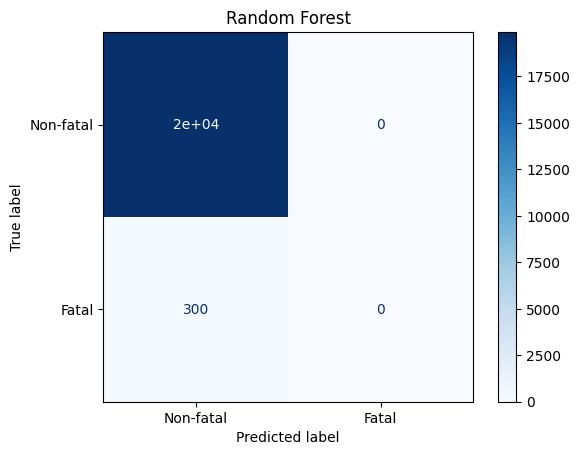

In [9]:
forest_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=12,
        min_samples_leaf=5,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

forest_model.fit(X_train, y_train)

forest_results = evaluate_model(
    "Random Forest",
    forest_model,
    X_test,
    y_test
)

Best parameters: {'classifier__C': 1.0, 'classifier__class_weight': None}
Best CV average precision: 0.037239654749219114

Tuned Logistic Regression
              precision    recall  f1-score   support

   Non-fatal       0.99      1.00      0.99     19886
       Fatal       0.00      0.00      0.00       300

    accuracy                           0.99     20186
   macro avg       0.49      0.50      0.50     20186
weighted avg       0.97      0.99      0.98     20186



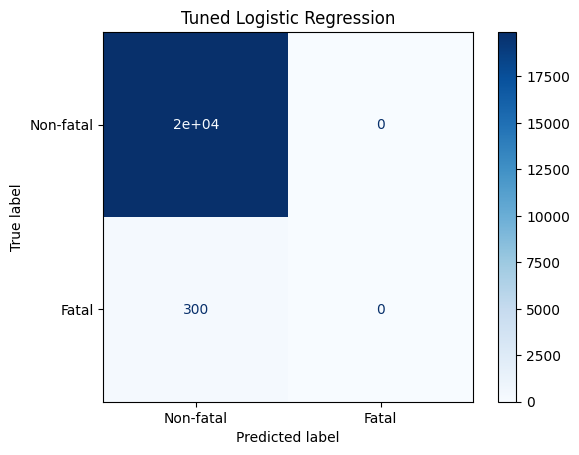

In [10]:
tuning_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE
    ))
])

parameter_grid = {
    "classifier__C": [0.1, 1.0, 10.0],
    "classifier__class_weight": [None, "balanced"]
}

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE
)

grid_search = GridSearchCV(
    estimator=tuning_pipeline,
    param_grid=parameter_grid,
    scoring="average_precision",
    cv=cv,
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best CV average precision:", grid_search.best_score_)

tuned_results = evaluate_model(
    "Tuned Logistic Regression",
    grid_search.best_estimator_,
    X_test,
    y_test
)

In [11]:
comparison = pd.DataFrame([
    baseline_results,
    weighted_results,
    forest_results,
    tuned_results
])

display(comparison.round(4))

comparison.to_csv(
    "baseline_model_comparison.csv",
    index=False
)

,Model,Accuracy,Precision,Recall,F1,Average Precision
0,Logistic Regression Baseline,0.9851,0.0000,0.0000,0.0000,0.0387
1,Class-weighted Logistic Regression,0.7140,0.0344,0.6733,0.0654,0.0389
2,Random Forest,0.9851,0.0000,0.0000,0.0000,0.0545
3,Tuned Logistic Regression,0.9851,0.0000,0.0000,0.0000,0.0387


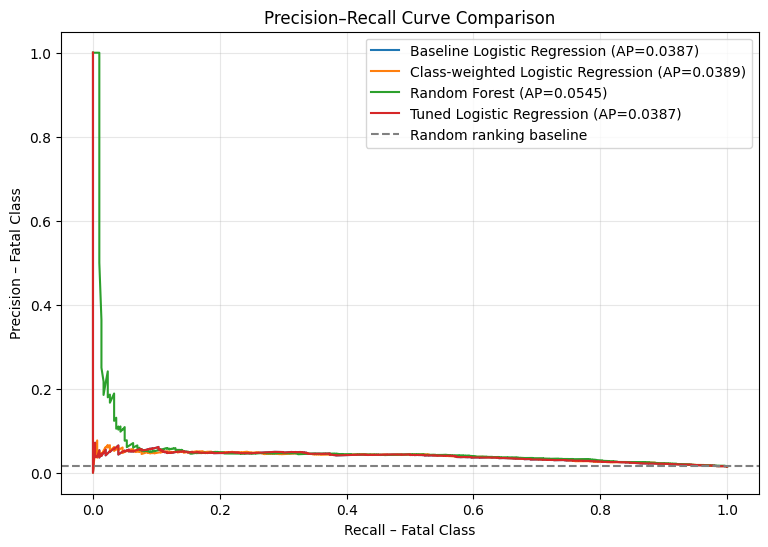

In [12]:
from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

models = {
    "Baseline Logistic Regression": baseline_model,
    "Class-weighted Logistic Regression": weighted_model,
    "Random Forest": forest_model,
    "Tuned Logistic Regression": grid_search.best_estimator_
}

plt.figure(figsize=(9, 6))

for name, model in models.items():
    probabilities = model.predict_proba(X_test)[:, 1]

    precision, recall, thresholds = precision_recall_curve(
        y_test, probabilities
    )

    ap = average_precision_score(
        y_test, probabilities
    )

    plt.plot(
        recall,
        precision,
        label=f"{name} (AP={ap:.4f})"
    )

plt.axhline(
    y=y_test.mean(),
    linestyle="--",
    color="gray",
    label="Random ranking baseline"
)

plt.xlabel("Recall – Fatal Class")
plt.ylabel("Precision – Fatal Class")
plt.title("Precision–Recall Curve Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [13]:
X_train_inner, X_val, y_train_inner, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.25,
    stratify=y_train,
    random_state=42
)

print("Inner training samples:", len(X_train_inner))
print("Validation samples:", len(X_val))
print("Final test samples:", len(X_test))

print("\nValidation target distribution:")
print(y_val.value_counts())

Inner training samples: 60555
Validation samples: 20186
Final test samples: 20186

Validation target distribution:
fatal_target
0    19885
1      301
Name: count, dtype: int64


In [14]:
threshold_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ))
])

threshold_model.fit(X_train_inner, y_train_inner)

val_probabilities = threshold_model.predict_proba(X_val)[:, 1]

print("Threshold candidate trained successfully!")

Threshold candidate trained successfully!


In [15]:
precision, recall, thresholds = precision_recall_curve(
    y_val,
    val_probabilities
)

f1_scores = (
    2 * precision[:-1] * recall[:-1] /
    (precision[:-1] + recall[:-1] + 1e-12)
)

best_index = np.argmax(f1_scores)
best_threshold = float(thresholds[best_index])

print(f"Best validation threshold: {best_threshold:.4f}")
print(f"Validation Precision: {precision[best_index]:.4f}")
print(f"Validation Recall: {recall[best_index]:.4f}")
print(f"Validation F1: {f1_scores[best_index]:.4f}")

Best validation threshold: 0.7664
Validation Precision: 0.0565
Validation Recall: 0.1728
Validation F1: 0.0852


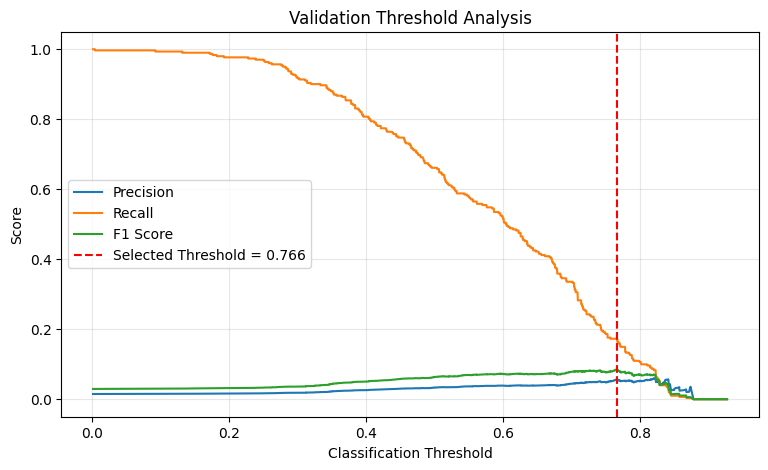

In [16]:
plt.figure(figsize=(9, 5))

plt.plot(thresholds, precision[:-1], label="Precision")
plt.plot(thresholds, recall[:-1], label="Recall")
plt.plot(thresholds, f1_scores, label="F1 Score")

plt.axvline(
    best_threshold,
    color="red",
    linestyle="--",
    label=f"Selected Threshold = {best_threshold:.3f}"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Validation Threshold Analysis")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Selected threshold: 0.7664424890491301

Final Classification Report:
              precision    recall  f1-score   support

   Non-fatal       0.99      0.96      0.97     19886
       Fatal       0.05      0.15      0.07       300

    accuracy                           0.94     20186
   macro avg       0.52      0.55      0.52     20186
weighted avg       0.97      0.94      0.96     20186



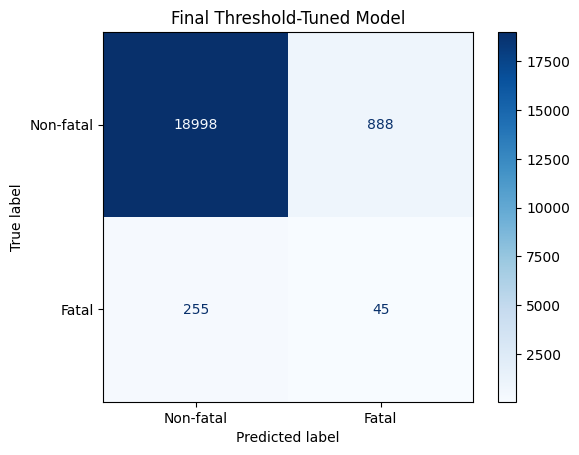

In [17]:
final_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ))
])

final_model.fit(X_train, y_train)

test_probabilities = final_model.predict_proba(X_test)[:, 1]

final_predictions = (
    test_probabilities >= best_threshold
).astype(int)

final_results = {
    "Model": "Logistic Regression + Threshold Tuning",
    "Accuracy": accuracy_score(y_test, final_predictions),
    "Precision": precision_score(
        y_test, final_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_test, final_predictions, zero_division=0
    ),
    "F1": f1_score(
        y_test, final_predictions, zero_division=0
    ),
    "Average Precision": average_precision_score(
        y_test, test_probabilities
    )
}

print("Selected threshold:", best_threshold)

print("\nFinal Classification Report:")
print(classification_report(
    y_test,
    final_predictions,
    target_names=["Non-fatal", "Fatal"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    final_predictions,
    display_labels=["Non-fatal", "Fatal"],
    cmap="Blues"
)

plt.title("Final Threshold-Tuned Model")
plt.show()

In [18]:
final_comparison = pd.DataFrame([
    baseline_results,
    weighted_results,
    forest_results,
    tuned_results,
    final_results
])

display(final_comparison.round(4))

final_comparison.to_csv(
    "final_model_comparison.csv",
    index=False
)

,Model,Accuracy,Precision,Recall,F1,Average Precision
0,Logistic Regression Baseline,0.9851,0.0000,0.0000,0.0000,0.0387
1,Class-weighted Logistic Regression,0.7140,0.0344,0.6733,0.0654,0.0389
2,Random Forest,0.9851,0.0000,0.0000,0.0000,0.0545
3,Tuned Logistic Regression,0.9851,0.0000,0.0000,0.0000,0.0387
4,Logistic Regression + Threshold Tuning,0.9434,0.0482,0.1500,0.0730,0.0389


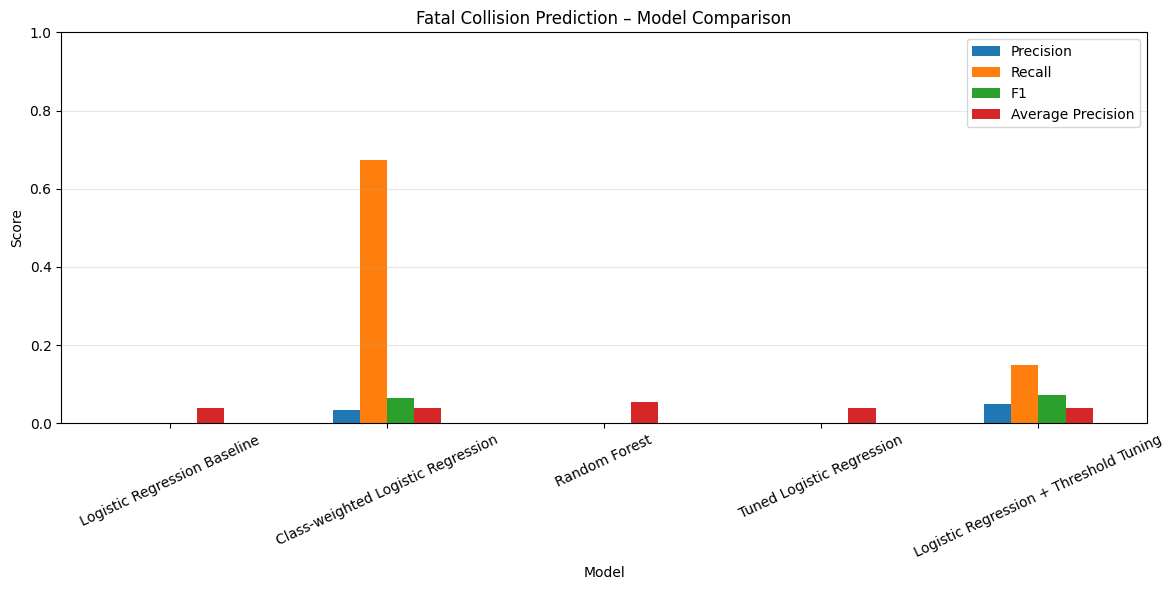

In [19]:
plot_data = final_comparison.set_index("Model")[
    ["Precision", "Recall", "F1", "Average Precision"]
]

plot_data.plot(
    kind="bar",
    figsize=(12, 6),
    rot=25
)

plt.title("Fatal Collision Prediction – Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [20]:
print("DATA QUALITY VALIDATION")
print("=" * 50)

print("Dataset shape:", df.shape)

print("\nMissing values in selected features:")
print(X.isnull().sum())

print("\nTarget distribution:")
print(y.value_counts())

print("\nTarget contains only 0 and 1:")
print(set(y.unique()).issubset({0, 1}))

print("\nDuplicate collision IDs:")
if "collision_index" in df.columns:
    print(df["collision_index"].duplicated().sum())
else:
    print("Collision index column not available")

print("\nTraining and testing shapes:")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

DATA QUALITY VALIDATION
Dataset shape: (100927, 45)

Missing values in selected features:
speed_limit                  3
number_of_vehicles           0
day_of_week                  0
road_type                    0
light_conditions             6
weather_conditions           0
road_surface_conditions    704
urban_or_rural_area          0
dtype: int64

Target distribution:
fatal_target
0    99425
1     1502
Name: count, dtype: int64

Target contains only 0 and 1:
True

Duplicate collision IDs:
0

Training and testing shapes:
X_train: (80741, 8)
X_test: (20186, 8)


In [21]:
print("TRAIN-TEST SEPARATION TEST")
print("=" * 50)

assert len(X_train) + len(X_test) == len(X)
assert len(y_train) + len(y_test) == len(y)

assert set(X_train.index).isdisjoint(
    set(X_test.index)
), "Training and testing rows overlap!"

assert set(y.unique()).issubset({0, 1})

print("PASS: Training and testing rows do not overlap.")
print("PASS: Dataset split is complete.")
print("PASS: Target labels are binary.")

TRAIN-TEST SEPARATION TEST
PASS: Training and testing rows do not overlap.
PASS: Dataset split is complete.
PASS: Target labels are binary.


In [22]:
print("MODEL PREDICTION TESTS")
print("=" * 50)

test_predictions = final_model.predict(X_test)
test_probabilities = final_model.predict_proba(X_test)[:, 1]

assert len(test_predictions) == len(X_test)
assert set(np.unique(test_predictions)).issubset({0, 1})

assert np.all(
    (test_probabilities >= 0) &
    (test_probabilities <= 1)
)

assert np.isfinite(test_probabilities).all()

print("PASS: Prediction count matches test samples.")
print("PASS: Predictions contain valid class labels.")
print("PASS: Probabilities are between 0 and 1.")
print("PASS: No invalid probability values.")

MODEL PREDICTION TESTS
PASS: Prediction count matches test samples.
PASS: Predictions contain valid class labels.
PASS: Probabilities are between 0 and 1.
PASS: No invalid probability values.


In [23]:
print("MISSING AND UNKNOWN VALUE TEST")
print("=" * 50)

sample = X_test.iloc[[0]].copy()

# Test 1: Missing numeric value
missing_sample = sample.copy()
missing_sample["speed_limit"] = np.nan

missing_prediction = final_model.predict(missing_sample)
print("PASS: Missing numeric value handled.")
print("Prediction:", missing_prediction[0])

# Test 2: Unknown categorical value
unknown_sample = sample.copy()
unknown_sample["road_type"] = 9999

unknown_prediction = final_model.predict(unknown_sample)
print("PASS: Unknown category handled.")
print("Prediction:", unknown_prediction[0])

# Test 3: All selected features missing
all_missing_sample = sample.copy()
all_missing_sample.loc[:, :] = np.nan

all_missing_prediction = final_model.predict(all_missing_sample)
print("PASS: All-missing sample processed.")
print("Prediction:", all_missing_prediction[0])

MISSING AND UNKNOWN VALUE TEST
PASS: Missing numeric value handled.
Prediction: 0
PASS: Unknown category handled.
Prediction: 0
PASS: All-missing sample processed.
Prediction: 0


In [24]:
print("FEATURE SUITABILITY AUDIT")
print("=" * 50)

excluded_columns = [
    "collision_severity",
    "enhanced_severity_collision",
    "number_of_casualties",
    "collision_index",
    "fatal_target"
]

used_features = X.columns.tolist()

print("Selected model features:")
for feature in used_features:
    print("-", feature)

print("\nOutcome / identifier leakage check:")

leaked = set(used_features).intersection(excluded_columns)

assert len(leaked) == 0, (
    f"Potential leakage columns detected: {leaked}"
)

print("PASS: Known outcome and ID columns excluded.")

print("\nManual review still required:")
print("- Are features available at prediction time?")
print("- Are STATS19 unknown codes handled correctly?")
print("- Does each row represent a unique collision?")

FEATURE SUITABILITY AUDIT
Selected model features:
- speed_limit
- number_of_vehicles
- day_of_week
- road_type
- light_conditions
- weather_conditions
- road_surface_conditions
- urban_or_rural_area

Outcome / identifier leakage check:
PASS: Known outcome and ID columns excluded.

Manual review still required:
- Are features available at prediction time?
- Are STATS19 unknown codes handled correctly?
- Does each row represent a unique collision?


In [25]:
test_results = []

def run_test(test_name, condition):
    status = "PASS" if condition else "FAIL"
    test_results.append({
        "Test": test_name,
        "Status": status
    })

run_test(
    "Train-test row separation",
    set(X_train.index).isdisjoint(set(X_test.index))
)

run_test(
    "Binary target labels",
    set(y.unique()).issubset({0, 1})
)

run_test(
    "Prediction count",
    len(final_predictions) == len(y_test)
)

run_test(
    "Probability range",
    np.all(
        (test_probabilities >= 0) &
        (test_probabilities <= 1)
    )
)

run_test(
    "Finite probability values",
    np.isfinite(test_probabilities).all()
)

run_test(
    "Known leakage columns excluded",
    len(leaked) == 0
)

testing_summary = pd.DataFrame(test_results)

display(testing_summary)

print(
    "Passed:",
    (testing_summary["Status"] == "PASS").sum(),
    "out of",
    len(testing_summary)
)

,Test,Status
0,Train-test row separation,PASS
1,Binary target labels,PASS
2,Prediction count,PASS
3,Probability range,PASS
4,Finite probability values,PASS
5,Known leakage columns excluded,PASS


Passed: 6 out of 6


In [26]:
testing_summary.to_csv(
    "model_testing_results.csv",
    index=False
)

print("Testing results saved successfully.")

Testing results saved successfully.


In [27]:
from sklearn.base import clone
from sklearn.metrics import balanced_accuracy_score

X_dev, X_final_test, y_dev, y_final_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=2026
)

X_final_train, X_final_val, y_final_train, y_final_val = train_test_split(
    X_dev, y_dev,
    test_size=0.25,
    stratify=y_dev,
    random_state=2026
)

print("Training:", X_final_train.shape)
print("Validation:", X_final_val.shape)
print("Testing:", X_final_test.shape)

print("\nFatal class proportions:")
print("Train:", y_final_train.mean())
print("Validation:", y_final_val.mean())
print("Test:", y_final_test.mean())

assert set(X_final_train.index).isdisjoint(X_final_val.index)
assert set(X_final_train.index).isdisjoint(X_final_test.index)
assert set(X_final_val.index).isdisjoint(X_final_test.index)

print("\nPASS: All three splits are separate.")

Training: (60555, 8)
Validation: (20186, 8)
Testing: (20186, 8)

Fatal class proportions:
Train: 0.014879035587482454
Validation: 0.014911324680471613
Test: 0.014861785395818885

PASS: All three splits are separate.


In [28]:
candidate_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),
    "Weighted Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=12,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    )
}

trained_candidates = {}

for name, classifier in candidate_models.items():
    model = Pipeline([
        ("preprocessing", clone(preprocessor)),
        ("classifier", classifier)
    ])

    model.fit(X_final_train, y_final_train)
    trained_candidates[name] = model

    print("Trained:", name)

print("\nAll candidate models trained.")

Trained: Logistic Regression
Trained: Weighted Logistic Regression
Trained: Random Forest

All candidate models trained.


In [29]:
validation_results = []
selected_thresholds = {}

for name, model in trained_candidates.items():

    probabilities = model.predict_proba(X_final_val)[:, 1]

    precision, recall, thresholds = precision_recall_curve(
        y_final_val, probabilities
    )

    f1_values = (
        2 * precision[:-1] * recall[:-1] /
        (precision[:-1] + recall[:-1] + 1e-12)
    )

    best_idx = np.argmax(f1_values)
    threshold = float(thresholds[best_idx])

    predictions = (probabilities >= threshold).astype(int)

    selected_thresholds[name] = threshold

    validation_results.append({
        "Model": name,
        "Threshold": threshold,
        "Precision": precision_score(
            y_final_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_final_val, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_final_val, predictions, zero_division=0
        ),
        "Average Precision": average_precision_score(
            y_final_val, probabilities
        )
    })

validation_table = pd.DataFrame(validation_results)

display(validation_table.round(4))

,Model,Threshold,Precision,Recall,F1,Average Precision
0,Logistic Regression,0.0346,0.0404,0.2890,0.0708,0.0330
1,Weighted Logistic Regression,0.7319,0.0412,0.2226,0.0695,0.0324
2,Random Forest,0.0345,0.0386,0.3090,0.0687,0.0353


In [30]:
best_row = validation_table.sort_values(
    by="F1",
    ascending=False
).iloc[0]

best_model_name = best_row["Model"]
final_threshold = selected_thresholds[best_model_name]

print("Selected model:", best_model_name)
print("Selected threshold:", round(final_threshold, 4))
print("Validation F1:", round(best_row["F1"], 4))

Selected model: Logistic Regression
Selected threshold: 0.0346
Validation F1: 0.0708


In [31]:
final_classifier = clone(
    candidate_models[best_model_name]
)

revised_final_model = Pipeline([
    ("preprocessing", clone(preprocessor)),
    ("classifier", final_classifier)
])

revised_final_model.fit(X_dev, y_dev)

print("Final model:", best_model_name)
print("Training completed successfully.")

Final model: Logistic Regression
Training completed successfully.


REVISED FINAL EVALUATION


,Model,Threshold,Accuracy,Balanced Accuracy,Precision,Recall,F1,Average Precision
0,Logistic Regression,0.0346,0.8879,0.6033,0.0433,0.31,0.076,0.041



Classification Report:
              precision    recall  f1-score   support

   Non-fatal       0.99      0.90      0.94     19886
       Fatal       0.04      0.31      0.08       300

    accuracy                           0.89     20186
   macro avg       0.52      0.60      0.51     20186
weighted avg       0.97      0.89      0.93     20186



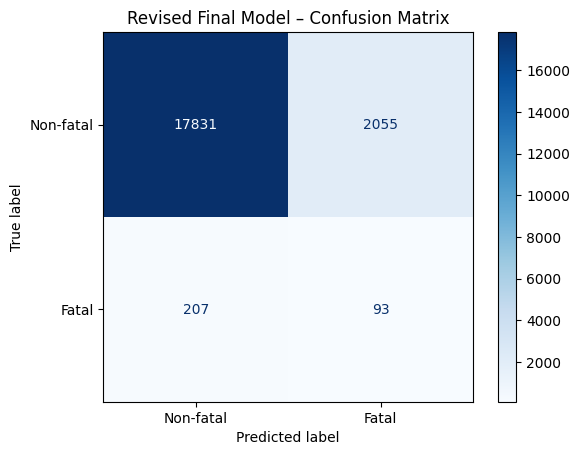

In [32]:
final_probabilities = revised_final_model.predict_proba(
    X_final_test
)[:, 1]

revised_predictions = (
    final_probabilities >= final_threshold
).astype(int)

revised_results = {
    "Model": best_model_name,
    "Threshold": final_threshold,
    "Accuracy": accuracy_score(
        y_final_test, revised_predictions
    ),
    "Balanced Accuracy": balanced_accuracy_score(
        y_final_test, revised_predictions
    ),
    "Precision": precision_score(
        y_final_test, revised_predictions,
        zero_division=0
    ),
    "Recall": recall_score(
        y_final_test, revised_predictions,
        zero_division=0
    ),
    "F1": f1_score(
        y_final_test, revised_predictions,
        zero_division=0
    ),
    "Average Precision": average_precision_score(
        y_final_test, final_probabilities
    )
}

print("REVISED FINAL EVALUATION")
print("=" * 50)

display(pd.DataFrame([revised_results]).round(4))

print("\nClassification Report:")
print(classification_report(
    y_final_test,
    revised_predictions,
    target_names=["Non-fatal", "Fatal"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_final_test,
    revised_predictions,
    display_labels=["Non-fatal", "Fatal"],
    cmap="Blues"
)

plt.title("Revised Final Model – Confusion Matrix")
plt.show()

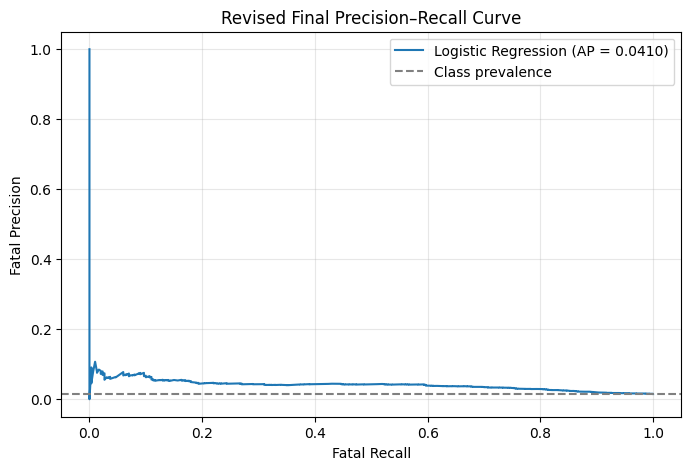

In [33]:
precision, recall, _ = precision_recall_curve(
    y_final_test,
    final_probabilities
)

ap = average_precision_score(
    y_final_test,
    final_probabilities
)

plt.figure(figsize=(8, 5))

plt.plot(
    recall,
    precision,
    label=f"{best_model_name} (AP = {ap:.4f})"
)

plt.axhline(
    y=y_final_test.mean(),
    linestyle="--",
    color="gray",
    label="Class prevalence"
)

plt.xlabel("Fatal Recall")
plt.ylabel("Fatal Precision")
plt.title("Revised Final Precision–Recall Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [34]:
revised_results_df = pd.DataFrame([revised_results])

revised_results_df.to_csv(
    "revised_final_results.csv",
    index=False
)

validation_table.to_csv(
    "revised_validation_results.csv",
    index=False
)

assert len(revised_predictions) == len(y_final_test)
assert set(np.unique(revised_predictions)).issubset({0, 1})
assert np.isfinite(final_probabilities).all()
assert 0 <= final_threshold <= 1

print("PASS: Prediction count verified")
print("PASS: Predicted labels verified")
print("PASS: Probabilities verified")
print("PASS: Selected threshold verified")
print("Results saved successfully!")

PASS: Prediction count verified
PASS: Predicted labels verified
PASS: Probabilities verified
PASS: Selected threshold verified
Results saved successfully!
